In [3]:
import sys, pandas as pd, numpy as np
print(sys.version.split()[0], pd.__version__, np.__version__)

3.11.9 2.2.3 2.2.6


Predicting Product Demand in E-Commerce Using Data Analysis and Machine Learning
Exploratory Data Analysis (EDA)
Dataset: Online Retail II

Team Members:
- Noor Btoosh – 202410877
- Diaa Al Ayyoub – 202320065
- Aya Aburajab – 202320127
- Sara Al Qaneer – 202320243


1. Environment Setup
- Python version: 3.11.9
- Virtual environment: .venv (venv)
- IDE: Visual Studio Code
- Notebook environment: Jupyter Notebook
- Required packages: pandas, numpy, matplotlib, seaborn, openpyxl, jupyter
Install the packages in the activated .venv environment:

2. Import Libraries

In [4]:
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Python:", sys.version.split()[0])
print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)

sns.set_theme(style="whitegrid")

Python: 3.11.9
Pandas: 2.2.3
NumPy: 2.2.6


3. Load the Dataset

In [5]:
from pathlib import Path

file_path = Path("../data/online_retail_II.xlsx")

try:
    sheet_1 = pd.read_excel(file_path, sheet_name="Year 2009-2010")
    sheet_2 = pd.read_excel(file_path, sheet_name="Year 2010-2011")
    df = pd.concat([sheet_1, sheet_2], ignore_index=True)
    print("Dataset loaded successfully.")
except FileNotFoundError:
    raise FileNotFoundError(
        "Place online_retail_II.xlsx inside the project's data folder."
    )
except Exception as error:
    raise RuntimeError(f"Could not load the dataset: {error}") from error

print("Dataset shape:", df.shape)

Dataset loaded successfully.
Dataset shape: (1067371, 8)


4. Inspect the Dataset

In [6]:
display(df.head())
display(df.tail())

print("Rows and columns:", df.shape)
print("Column names:", df.columns.tolist())

df.info()

display(df.describe(include="all").T)

print("Missing values:")
display(df.isna().sum().to_frame("Missing Values"))

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
1067366,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,2011-12-09 12:50:00,2.10,12680.0,France
1067367,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,2011-12-09 12:50:00,4.15,12680.0,France
1067368,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,2011-12-09 12:50:00,4.15,12680.0,France
1067369,581587,22138,BAKING SET 9 PIECE RETROSPOT,3,2011-12-09 12:50:00,4.95,12680.0,France
1067370,581587,POST,POSTAGE,1,2011-12-09 12:50:00,18.00,12680.0,France


Rows and columns: (1067371, 8)
Column names: ['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'Price', 'Customer ID', 'Country']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1067371 entries, 0 to 1067370
Data columns (total 8 columns):
 #   Column       Non-Null Count    Dtype         
---  ------       --------------    -----         
 0   Invoice      1067371 non-null  object        
 1   StockCode    1067371 non-null  object        
 2   Description  1062989 non-null  object        
 3   Quantity     1067371 non-null  int64         
 4   InvoiceDate  1067371 non-null  datetime64[ns]
 5   Price        1067371 non-null  float64       
 6   Customer ID  824364 non-null   float64       
 7   Country      1067371 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 65.1+ MB


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
Invoice,1067371.0,53628.0,537434.0,1350.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
StockCode,1067371,5305,85123A,5829,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Description,1062989,5698,WHITE HANGING HEART T-LIGHT HOLDER,5918,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Quantity,1067371.0,NaN,NaN,NaN,9.938898,-80995.0,1.0,3.0,10.0,80995.0,172.705794
InvoiceDate,1067371,NaN,NaN,NaN,2011-01-02 21:13:55.394028544,2009-12-01 07:45:00,2010-07-09 09:46:00,2010-12-07 15:28:00,2011-07-22 10:23:00,2011-12-09 12:50:00,NaN
Price,1067371.0,NaN,NaN,NaN,4.649388,-53594.36,1.25,2.1,4.15,38970.0,123.553059
Customer ID,824364.0,NaN,NaN,NaN,15324.638504,12346.0,13975.0,15255.0,16797.0,18287.0,1697.46445
Country,1067371,43,United Kingdom,981330,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Missing values:


,Missing Values
Invoice,0
StockCode,0
Description,4382
Quantity,0
InvoiceDate,0
Price,0
Customer ID,243007
Country,0


5. Handle Missing Values

In [7]:
print("Missing values before handling:")
display(df.isna().sum().to_frame("Missing Before"))

df_clean = df.copy()

# Fill missing product descriptions.
df_clean["Description"] = df_clean["Description"].fillna("Unknown")

# Convert fields needed for analysis to their appropriate data types.
df_clean["InvoiceDate"] = pd.to_datetime(df_clean["InvoiceDate"], errors="coerce")
df_clean["Quantity"] = pd.to_numeric(df_clean["Quantity"], errors="coerce")
df_clean["Price"] = pd.to_numeric(df_clean["Price"], errors="coerce")

# Remove rows missing essential transaction information.
df_clean = df_clean.dropna(
    subset=["Invoice", "StockCode", "Quantity", "InvoiceDate", "Price"]
).copy()

print("Missing values after handling:")
display(df_clean.isna().sum().to_frame("Missing After"))
print("Shape after handling missing values:", df_clean.shape)

Missing values before handling:


,Missing Before
Invoice,0
StockCode,0
Description,4382
Quantity,0
InvoiceDate,0
Price,0
Customer ID,243007
Country,0


Missing values after handling:


,Missing After
Invoice,0
StockCode,0
Description,0
Quantity,0
InvoiceDate,0
Price,0
Customer ID,243007
Country,0


Shape after handling missing values: (1067371, 8)


6. Handle Duplicate Rows

In [8]:
duplicate_count = df_clean.duplicated().sum()
print("Duplicate rows before removal:", duplicate_count)

df_clean = df_clean.drop_duplicates().copy()

print("Duplicate rows after removal:", df_clean.duplicated().sum())
print("Shape after removing duplicates:", df_clean.shape)

Duplicate rows before removal: 34335
Duplicate rows after removal: 0
Shape after removing duplicates: (1033036, 8)


7. Handle Data Types

In [9]:
df_clean["InvoiceDate"] = pd.to_datetime(df_clean["InvoiceDate"], errors="coerce")
df_clean["Quantity"] = pd.to_numeric(df_clean["Quantity"], errors="coerce")
df_clean["Price"] = pd.to_numeric(df_clean["Price"], errors="coerce")
df_clean["Customer ID"] = pd.to_numeric(
    df_clean["Customer ID"], errors="coerce"
).astype("Int64")

print("Data types after conversion:")
print(df_clean.dtypes)

Data types after conversion:
Invoice                object
StockCode              object
Description            object
Quantity                int64
InvoiceDate    datetime64[ns]
Price                 float64
Customer ID             Int64
Country                object
dtype: object


8. Prepare Data for Sales and Demand Analysis
For the sales and demand analysis, cancelled invoices (invoice numbers beginning with C), non-positive quantities, and non-positive prices are excluded. This defines the analyzed demand as positive quantities sold. The cleaned dataset remains available in df_clean.

In [10]:
df_clean["IsCancelled"] = df_clean["Invoice"].astype(str).str.startswith("C")

sales_df = df_clean.loc[
    (~df_clean["IsCancelled"]) &
    (df_clean["Quantity"] > 0) &
    (df_clean["Price"] > 0)
].copy()

sales_df["TotalSales"] = sales_df["Quantity"] * sales_df["Price"]

print("Cleaned dataset shape:", df_clean.shape)
print("Sales analysis dataset shape:", sales_df.shape)
display(sales_df.head())

Cleaned dataset shape: (1033036, 9)
Sales analysis dataset shape: (1007913, 10)


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,IsCancelled,TotalSales
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085,United Kingdom,False,83.4
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,United Kingdom,False,81.0
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,United Kingdom,False,81.0
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085,United Kingdom,False,100.8
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085,United Kingdom,False,30.0


9. Filtering

In [11]:
high_quantity_sales = sales_df.loc[sales_df["Quantity"] > 10]
uk_sales = sales_df.loc[sales_df["Country"] == "United Kingdom"]

print("Transactions with quantity greater than 10:", len(high_quantity_sales))
display(high_quantity_sales.head())

print("United Kingdom transactions:", len(uk_sales))
display(uk_sales.head())

Transactions with quantity greater than 10: 255021


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,IsCancelled,TotalSales
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085,United Kingdom,False,83.4
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,United Kingdom,False,81.0
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,United Kingdom,False,81.0
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085,United Kingdom,False,100.8
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085,United Kingdom,False,30.0


United Kingdom transactions: 926038


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,IsCancelled,TotalSales
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085,United Kingdom,False,83.4
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,United Kingdom,False,81.0
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085,United Kingdom,False,81.0
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085,United Kingdom,False,100.8
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085,United Kingdom,False,30.0


10. GroupBy

In [12]:
product_sales = (
    sales_df.groupby("StockCode", as_index=False)
    .agg(TotalQuantity=("Quantity", "sum"))
    .sort_values("TotalQuantity", ascending=False)
)

country_sales = (
    sales_df.groupby("Country", as_index=False)
    .agg(TotalSales=("TotalSales", "sum"))
    .sort_values("TotalSales", ascending=False)
)

display(product_sales.head(10))
display(country_sales.head(10))

,StockCode,TotalQuantity
2963,84077,106139
4441,85099B,96757
490,21212,94884
4456,85123A,94203
1308,22197,88499
2673,23843,80995
3132,84879,80082
2228,23166,78033
50,17003,70369
1121,21977,56061


,Country,TotalSales
40,United Kingdom,1.741020e+07
11,EIRE,6.587673e+05
26,Netherlands,5.540381e+05
15,Germany,4.250197e+05
14,France,3.504561e+05
0,Australia,1.692835e+05
34,Spain,1.083325e+05
36,Switzerland,1.006856e+05
35,Sweden,9.186982e+04
10,Denmark,6.858069e+04


11. Merge

In [13]:
product_info = (
    sales_df[["StockCode", "Description"]]
    .drop_duplicates(subset="StockCode")
)

merged_data = pd.merge(
    product_sales,
    product_info,
    on="StockCode",
    how="left"
)

display(merged_data.head(10))

,StockCode,TotalQuantity,Description
0,84077,106139,WORLD WAR 2 GLIDERS ASSTD DESIGNS
1,85099B,96757,JUMBO BAG RED WHITE SPOTTY
2,21212,94884,PACK OF 72 RETRO SPOT CAKE CASES
3,85123A,94203,WHITE HANGING HEART T-LIGHT HOLDER
4,22197,88499,"POPCORN HOLDER , SMALL"
5,23843,80995,"PAPER CRAFT , LITTLE BIRDIE"
6,84879,80082,ASSORTED COLOUR BIRD ORNAMENT
7,23166,78033,MEDIUM CERAMIC TOP STORAGE JAR
8,17003,70369,BROCADE RING PURSE
9,21977,56061,PACK OF 60 PINK PAISLEY CAKE CASES


12. Pivot Table

In [14]:
sales_df["Year"] = sales_df["InvoiceDate"].dt.year
sales_df["Month"] = sales_df["InvoiceDate"].dt.month

monthly_pivot = pd.pivot_table(
    sales_df,
    values="TotalSales",
    index="Month",
    columns="Year",
    aggfunc="sum",
    fill_value=0
)

display(monthly_pivot)

Year,2009,2010,2011
Month,,,
1,0.00,651155.112,689811.610
2,0.00,551504.726,522545.560
3,0.00,830915.261,716215.260
4,0.00,678875.252,536968.491
5,0.00,657705.500,769296.610
6,0.00,749537.310,760547.010
7,0.00,648810.270,718076.121
8,0.00,695251.910,757841.380
9,0.00,921696.991,1056435.192


13. Descriptive Statistics

In [15]:
display(sales_df[["Quantity", "Price", "TotalSales"]].describe())

print("Mean quantity:", sales_df["Quantity"].mean())
print("Median quantity:", sales_df["Quantity"].median())
print("Mean price:", sales_df["Price"].mean())
print("Total sales:", sales_df["TotalSales"].sum())

,Quantity,Price,TotalSales
count,1.007913e+06,1.007913e+06,1.007913e+06
mean,1.111718e+01,4.074252e+00,2.031550e+01
std,1.284700e+02,5.043045e+01,2.057158e+02
min,1.000000e+00,1.000000e-03,1.000000e-03
25%,1.000000e+00,1.250000e+00,4.130000e+00
50%,4.000000e+00,2.100000e+00,1.008000e+01
75%,1.200000e+01,4.130000e+00,1.770000e+01
max,8.099500e+04,2.511109e+04,1.684696e+05


Mean quantity: 11.117177772287887
Median quantity: 4.0
Mean price: 4.07425186300802
Total sales: 20476260.447999995


14. NumPy Calculations

In [16]:
quantities = sales_df["Quantity"].to_numpy()
prices = sales_df["Price"].to_numpy()

print("Mean quantity:", np.mean(quantities))
print("Median quantity:", np.median(quantities))
print("Standard deviation:", np.std(quantities))
print("Minimum quantity:", np.min(quantities))
print("Maximum quantity:", np.max(quantities))
print("25th percentile:", np.percentile(quantities, 25))
print("75th percentile:", np.percentile(quantities, 75))
print("Total sales calculated with NumPy:", np.sum(quantities * prices))

Mean quantity: 11.117177772287887
Median quantity: 4.0
Standard deviation: 128.46996162373065
Minimum quantity: 1
Maximum quantity: 80995
25th percentile: 1.0
75th percentile: 12.0
Total sales calculated with NumPy: 20476260.447999995


15. Visualisation 1 – Top 10 Products by Quantity Sold
Insight: The output identifies the product with the highest total quantity sold. The chart compares the ten products with the highest total quantities.

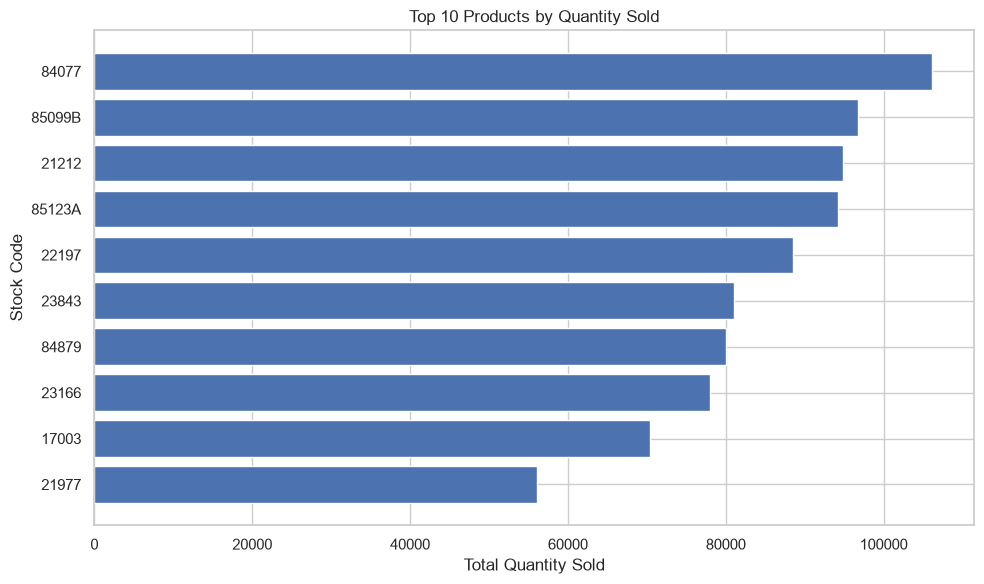

Insight: Product 84077 has the highest total quantity sold: 106,139.


In [17]:
top_products = product_sales.head(10).sort_values("TotalQuantity")

plt.figure(figsize=(10, 6))
plt.barh(top_products["StockCode"].astype(str), top_products["TotalQuantity"])
plt.title("Top 10 Products by Quantity Sold")
plt.xlabel("Total Quantity Sold")
plt.ylabel("Stock Code")
plt.tight_layout()
plt.show()

highest_product = product_sales.iloc[0]
print(
    f"Insight: Product {highest_product['StockCode']} has the highest "
    f"total quantity sold: {highest_product['TotalQuantity']:,.0f}."
)

16. Visualisation 2 – Top 10 Countries by Sales
Insight: The output identifies the country with the highest total sales. The chart compares total sales across the ten leading countries.

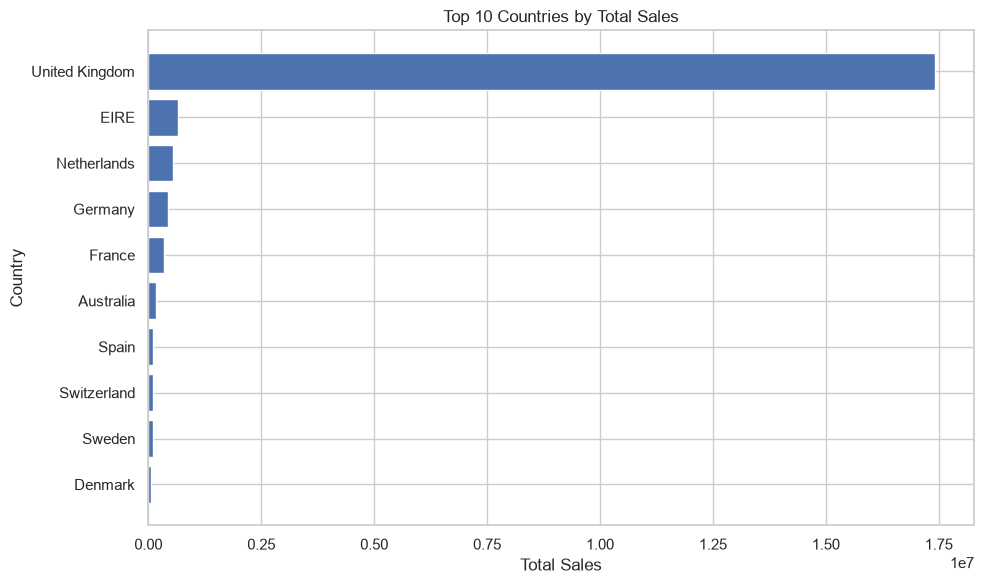

Insight: United Kingdom has the highest total sales: 17,410,196.12.


In [18]:
top_countries = country_sales.head(10).sort_values("TotalSales")

plt.figure(figsize=(10, 6))
plt.barh(top_countries["Country"], top_countries["TotalSales"])
plt.title("Top 10 Countries by Total Sales")
plt.xlabel("Total Sales")
plt.ylabel("Country")
plt.tight_layout()
plt.show()

highest_country = country_sales.iloc[0]
print(
    f"Insight: {highest_country['Country']} has the highest total sales: "
    f"{highest_country['TotalSales']:,.2f}."
)

17. Visualisation 3 – Monthly Sales Trend
Insight: The output identifies the month with the highest total sales. The line chart shows how sales change over time.

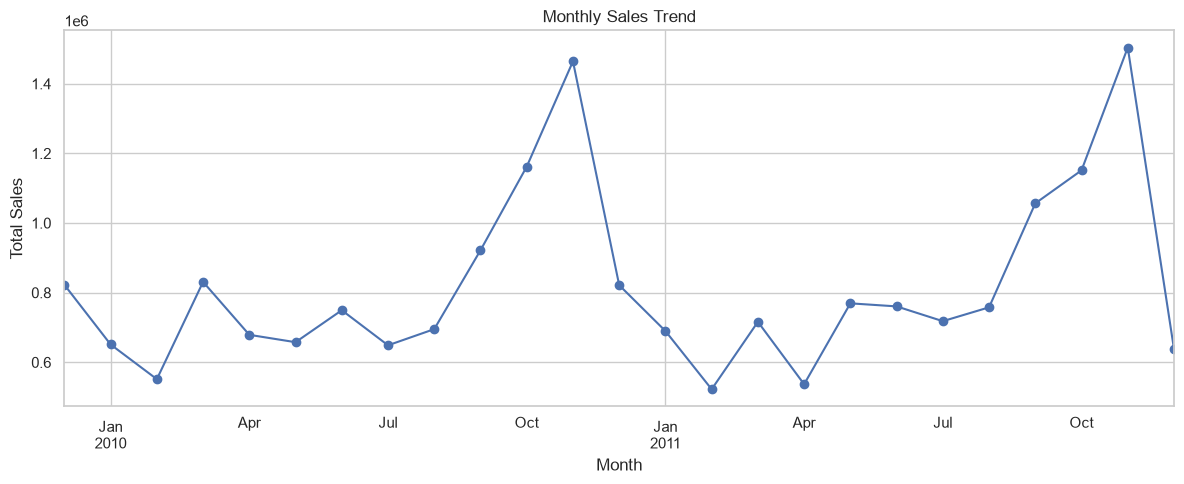

Insight: The highest monthly sales occurred in November 2011, with total sales of 1,503,866.78.


In [19]:
monthly_sales = (
    sales_df.set_index("InvoiceDate")["TotalSales"]
    .resample("MS")
    .sum()
)

plt.figure(figsize=(12, 5))
monthly_sales.plot(marker="o")
plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.tight_layout()
plt.show()

peak_month = monthly_sales.idxmax()
print(
    f"Insight: The highest monthly sales occurred in {peak_month:%B %Y}, "
    f"with total sales of {monthly_sales.max():,.2f}."
)

18. Visualisation 4 – Distribution of Quantity Sold
The chart displays quantities up to the 99th percentile to make the main distribution easier to read.

Insight: The output compares the mean and median transaction quantities and reports the 99th percentile used as the chart limit.

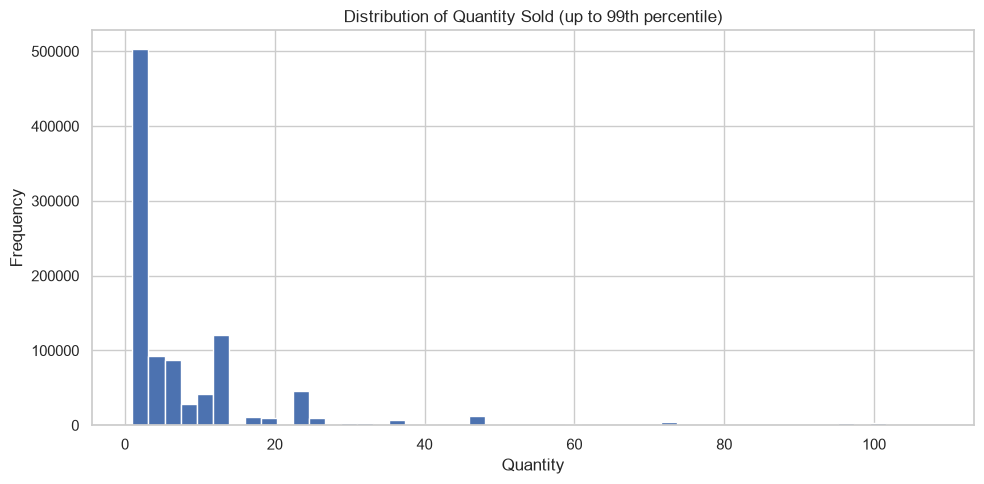

Insight: Mean quantity = 11.12; median quantity = 4.00. The chart is limited to the 99th percentile (108.00).


In [20]:
quantity_limit = sales_df["Quantity"].quantile(0.99)
quantity_to_plot = sales_df.loc[
    sales_df["Quantity"] <= quantity_limit, "Quantity"
]

plt.figure(figsize=(10, 5))
plt.hist(quantity_to_plot, bins=50)
plt.title("Distribution of Quantity Sold (up to 99th percentile)")
plt.xlabel("Quantity")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

print(
    f"Insight: Mean quantity = {sales_df['Quantity'].mean():.2f}; "
    f"median quantity = {sales_df['Quantity'].median():.2f}. "
    f"The chart is limited to the 99th percentile ({quantity_limit:.2f})."
)

19. Visualisation 5 – Monthly Demand for the Top 5 Products
Insight: The chart compares the monthly quantities sold for the five products with the highest total quantities and shows how their demand changes over time.

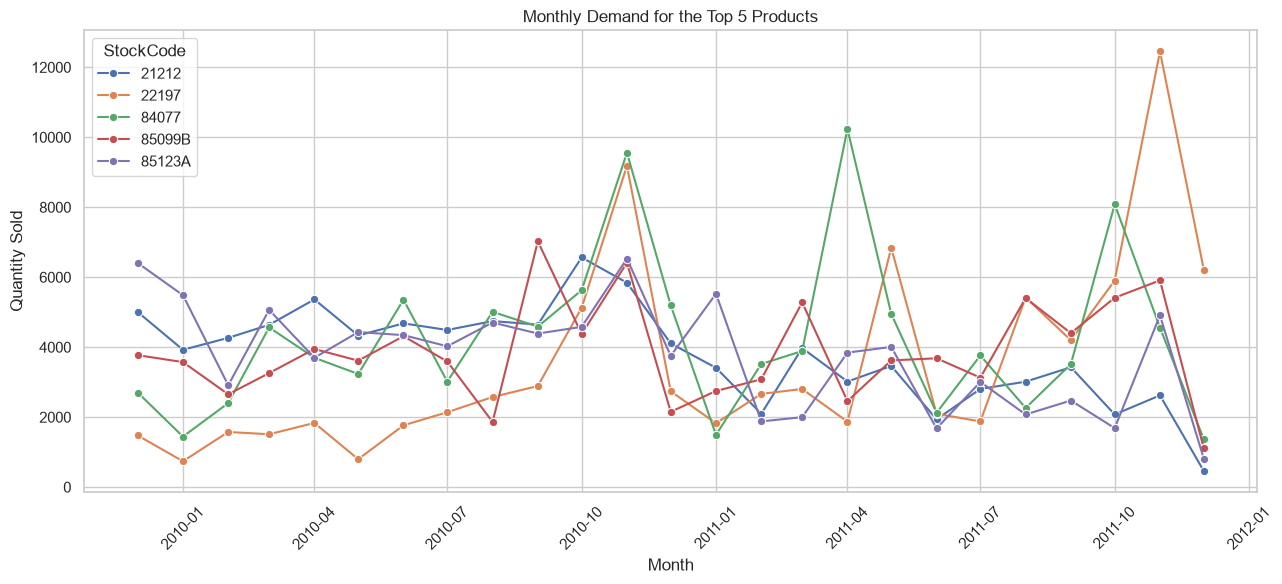

Insight: The lines compare monthly demand patterns for the five products with the highest total quantities sold.


In [21]:
top_5_codes = product_sales.head(5)["StockCode"]

top_5_sales = sales_df.loc[
    sales_df["StockCode"].isin(top_5_codes)
].copy()

top_5_sales["MonthPeriod"] = (
    top_5_sales["InvoiceDate"].dt.to_period("M").dt.to_timestamp()
)

monthly_demand = (
    top_5_sales.groupby(["MonthPeriod", "StockCode"], as_index=False)
    .agg(Quantity=("Quantity", "sum"))
)

plt.figure(figsize=(13, 6))
sns.lineplot(
    data=monthly_demand,
    x="MonthPeriod",
    y="Quantity",
    hue="StockCode",
    marker="o"
)
plt.title("Monthly Demand for the Top 5 Products")
plt.xlabel("Month")
plt.ylabel("Quantity Sold")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

print(
    "Insight: The lines compare monthly demand patterns for the five "
    "products with the highest total quantities sold."
)

20. Advanced Python – List Comprehension

In [22]:
numeric_columns = [
    column
    for column in sales_df.columns
    if pd.api.types.is_numeric_dtype(sales_df[column])
]

print("Numeric columns:", numeric_columns)

Numeric columns: ['Quantity', 'Price', 'Customer ID', 'IsCancelled', 'TotalSales', 'Year', 'Month']


21. Advanced Python – Generator

In [23]:
def stock_code_generator(stock_codes):
    for stock_code in stock_codes:
        yield stock_code

unique_stock_codes = sales_df["StockCode"].dropna().unique()

for index, stock_code in enumerate(stock_code_generator(unique_stock_codes)):
    if index == 5:
        break
    print(stock_code)

85048
79323P
79323W
22041
21232


22. Advanced Python – Lambda Function

In [24]:
sales_df["PriceCategory"] = sales_df["Price"].apply(
    lambda price: "Low Price" if price < 5 else "High Price"
)

display(sales_df[["StockCode", "Price", "PriceCategory"]].head())

,StockCode,Price,PriceCategory
0,85048,6.95,High Price
1,79323P,6.75,High Price
2,79323W,6.75,High Price
3,22041,2.10,Low Price
4,21232,1.25,Low Price


23. Advanced Python – Function with Type Hints

In [25]:
def calculate_total_sales(data: pd.DataFrame) -> float:
    return float((data["Quantity"] * data["Price"]).sum())

total_sales = calculate_total_sales(sales_df)
print("Total sales:", total_sales)

Total sales: 20476260.447999995


24. Advanced Python – Error Handling

In [26]:
try:
    average_quantity = sales_df["Quantity"].mean()
    print("Average quantity:", average_quantity)
except KeyError as error:
    print("Column not found:", error)
except Exception as error:
    print("An error occurred:", error)

Average quantity: 11.117177772287887
